In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [1]:
!pip install --upgrade torch torchvision torchaudio

Using cache found in /root/.cache/torch/hub/intel-isl_MiDaS_master
Using cache found in /root/.cache/torch/hub/intel-isl_MiDaS_master


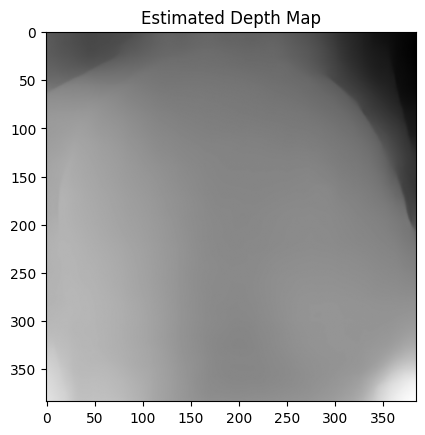

In [23]:
import cv2
import matplotlib.pyplot as plt
import torch
import torchvision.transforms as transforms
import numpy as np
from PIL import Image

# Load the pre-trained MiDaS model
model_type = "DPT_Large"
midas = torch.hub.load("intel-isl/MiDaS", model_type)
midas.eval()

# Load transforms to resize the image
midas_transforms = torch.hub.load("intel-isl/MiDaS", "transforms")
transform = midas_transforms.dpt_transform

# Load the image
image_path = '/content/drive/My Drive/98 Muse-1.png'
input_image = Image.open(image_path).convert("RGB")

# Explicitly resize the image before applying the transform
desired_size = (384, 384)  # Choose a suitable size
input_image = input_image.resize(desired_size, Image.Resampling.LANCZOS) # Use high-quality resampling

# Convert the PIL Image to a NumPy array
input_image_np = np.array(input_image)

# Check if the image dimensions are valid
if input_image_np.shape[0] <= 0 or input_image_np.shape[1] <= 0:
    raise ValueError("Invalid image dimensions. Image height and width must be greater than 0.")

# Apply the MiDaS transform
input_image = transform(input_image_np)

# Remove the redundant ToTensor call as the transform likely already handles this
# input_image = transforms.ToTensor()(input_image) # This line is removed

# Move image and model to the appropriate device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
midas.to(device)
input_image = input_image.to(device)

# Perform depth estimation
with torch.no_grad():
    prediction = midas(input_image)

# Convert the prediction to a numpy array
depth_map = prediction.squeeze().cpu().numpy()

# Display the depth map
plt.imshow(depth_map, cmap='gray')
plt.title('Estimated Depth Map')
plt.show()

In [20]:
import numpy as np

# Normalize the depth map
depth_map_normalized = (depth_map - depth_map.min()) / (depth_map.max() - depth_map.min())

In [21]:
h, w = depth_map_normalized.shape
x = np.linspace(0, w, w)
y = np.linspace(0, h, h)
X, Y = np.meshgrid(x, y)

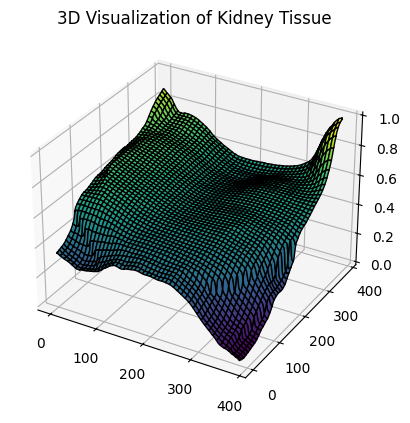

In [22]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Create a 3D plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot the surface
ax.plot_surface(X, Y, depth_map_normalized, cmap='viridis', edgecolor='k')

plt.title('3D Visualization of Kidney Tissue')
plt.show()